# Part 2 — Indexing and Evaluation: Indexing

This notebook builds the inverted index over the pre-processed corpus of Part 1, defines five test queries chosen by term popularity, and ranks results with TF-IDF using conjunctive (AND) semantics.

The code lives in `myapp/search/indexing.py` (index) and `myapp/search/algorithms.py` (query processing, AND retrieval, TF-IDF), so the web app can reuse it.

In [4]:
import sys
from pathlib import Path
import time
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import Counter
from myapp.search.indexing import build_inverted_index, save_index, load_index
from myapp.search.algorithms import process_query, conjunctive_retrieve, rank_tfidf, search_in_corpus

#Locate the project root (first parent folder containing `myapp`)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "myapp").exists())
sys.path.insert(0, str(ROOT))

## 1. Load the processed corpus

In [2]:
processed = pd.read_pickle(ROOT / "data" / "processed_corpus.pkl")
print(processed.shape)
processed[["pid", "title", "terms"]].head(3)

(28080, 21)


,pid,title,terms
TKPFCZ9EA7H5FYZH,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant, yorker..."
TKPFCZ9EJZV2UVRZ,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,"[solid, men, blue, track, pant, yorker, trackp..."
TKPFCZ9EHFCY5Z4Y,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant, yorker, ..."


## 2. Build the inverted index

`vocab` maps term → term_id; `postings` maps term_id → {pid: tf}. Document frequencies and TF-IDF vector norms are precomputed for cosine ranking.

In [3]:
t0 = time.time()
index = build_inverted_index(processed)
print(f"Built in {time.time() - t0:.2f}s | documents: {index.n_docs} | vocabulary: {len(index.vocab)}")
save_index(index, str(ROOT / "data" / "inverted_index.pkl"))

postings_len = pd.Series({t: len(p) for t, p in index.postings.items()})
print(f"Postings per term: mean {postings_len.mean():.1f}, median {postings_len.median():.0f}, max {postings_len.max()}")

Built in 0.31s | documents: 28080 | vocabulary: 5053
Postings per term: mean 147.3, median 7, max 21690


### Sanity check on an example corpus

In [5]:
toy = pd.DataFrame({"pid": ["a", "b", "c"],
                    "terms": [["jean", "blue", "blue"], ["jean", "red"], ["shirt"]]})
toy_index = build_inverted_index(toy)
print(search_in_corpus("blue jean", toy_index))   # only 'a' has both terms (AND)
print(search_in_corpus("jean", toy_index))        # 'b' is shorter, so it ranks above 'a'

[('a', 0.9903633217954314)]
[('b', 0.34624155305796134), ('a', 0.21297775513327716)]


In [6]:
# postings counts must equal the term counts of the documents
for pid in random.sample(list(processed["pid"]), 200):
    terms = processed.loc[processed["pid"] == pid, "terms"].iloc[0]
    for term, tf in Counter(terms).items():
        assert index.postings[index.vocab[term]][pid] == tf
print("Index consistent with the corpus")

Index consistent with the corpus


## 3. Term popularity and choice of test queries

In [8]:
inv_vocab = {tid: term for term, tid in index.vocab.items()}
total_tf = {tid: sum(p.values()) for tid, p in index.postings.items()}
popularity = pd.DataFrame({
    "term": [inv_vocab[t] for t in index.df],
    "df": list(index.df.values()),
    "total_tf": [total_tf[t] for t in index.df],
    "idf": [index.idf(t) for t in index.df],
}).sort_values("df", ascending=False).reset_index(drop=True)
popularity.head(5)

,term,df,total_tf,idf
0,cotton,21690,33252,0.258206
1,sleev,17908,24134,0.449810
2,topwear,15310,15310,0.606551
3,neck,14569,41145,0.656162
4,men,14123,26213,0.687253


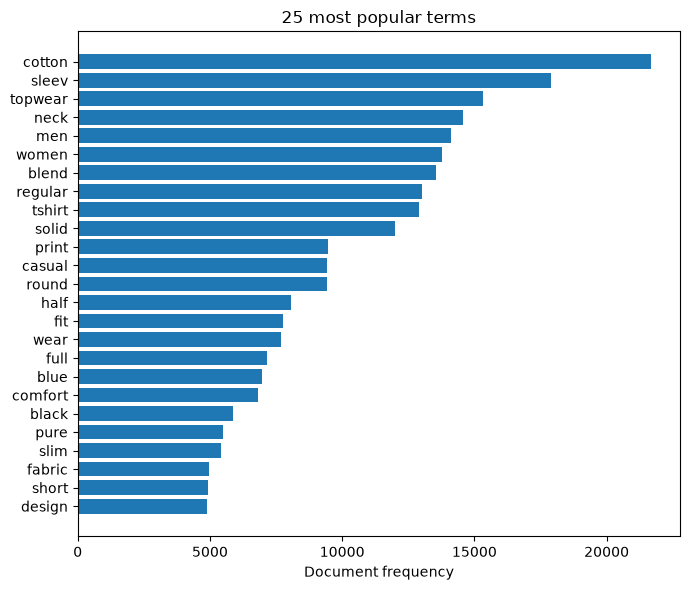

In [9]:
top = popularity.head(25).iloc[::-1]
plt.figure(figsize=(7, 6))
plt.barh(top["term"], top["df"])
plt.xlabel("Document frequency")
plt.title("25 most popular terms")
plt.tight_layout()
plt.show()

The most frequent terms (`cotton`, `sleev`, `men`, `women`, `tshirt`, `fit`, `blue`, `black`, `slim`...) describe product type, gender, fit, material and colour. The five test queries combine popular terms of these kinds, with different lengths and different numbers of expected matches.

In [10]:
queries = {
    "q1": "men round neck cotton tshirt",
    "q2": "women casual cotton blend topwear",
    "q3": "men slim fit blue jeans",
    "q4": "black solid cotton polo",
    "q5": "women full sleeve printed sweatshirt",
}
rows = []
for qid, q in queries.items():
    terms = process_query(q)
    matches = conjunctive_retrieve(terms, index)
    rows.append({"query": qid, "text": q, "processed terms": terms,
                 "min df": min(index.df[index.vocab[t]] for t in terms), "AND matches": len(matches)})
pd.DataFrame(rows)

,query,text,processed terms,min df,AND matches
0,q1,men round neck cotton tshirt,"[men, round, neck, cotton, tshirt]",9408,3678
1,q2,women casual cotton blend topwear,"[women, casual, cotton, blend, topwear]",9443,1548
2,q3,men slim fit blue jeans,"[men, slim, fit, blue, jean]",2430,104
3,q4,black solid cotton polo,"[black, solid, cotton, polo]",3029,222
4,q5,women full sleeve printed sweatshirt,"[women, full, sleev, print, sweatshirt]",1417,341


## 4. Conjunctive retrieval and TF-IDF ranking

A document matches only if it contains every query term. Matching documents are ranked by cosine similarity between TF-IDF vectors, with weights `(1 + log tf) · log(N / df)`.

In [11]:
titles = processed.set_index("pid")["title"]

def show(query, k=10):
    results = search_in_corpus(query, index, top_k=k)
    print(f"Query: {query!r} -> terms {process_query(query)}")
    return pd.DataFrame([(pid, titles[pid], round(score, 4)) for pid, score in results],
                        columns=["pid", "title", "tfidf score"])

In [12]:
show(queries["q1"])

Query: 'men round neck cotton tshirt' -> terms ['men', 'round', 'neck', 'cotton', 'tshirt']


,pid,title,tfidf score
0,TSHFKJESD3ZAESPF,Solid Men Round Neck Black T-Shirt,0.7492
1,TSHFUSKPWUZSP6F6,Printed Men Round Neck Black T-Shirt,0.7233
2,TSHFKJEVTH5ZYDAB,Solid Men Round Neck Black T-Shirt,0.7205
3,TSHFKJF5XCHHHZAV,Solid Men Round Neck Red T-Shirt,0.6393
4,TSHFKAJTQMPRVPKD,Solid Men Round Neck Dark Blue T-Shirt,0.6321
5,TSHFZCW9P4AVCUXN,"Solid Men Round Neck White, Black, Grey T-Shir...",0.5771
6,TSHFNQW3ZATACXE3,Solid Men Round Neck White T-Shirt,0.5591
7,TSHFNYTUXFE5GWQC,Solid Men Round Neck White T-Shirt,0.5564
8,TSHFUMQFEBDDH7GY,Solid Men Round Neck White T-Shirt,0.5564
9,TSHFNYTT7XQTV6HF,Solid Men Round Neck Grey T-Shirt,0.5491


In [13]:
show(queries["q2"])

Query: 'women casual cotton blend topwear' -> terms ['women', 'casual', 'cotton', 'blend', 'topwear']


,pid,title,tfidf score
0,TSHF743TG8GC6ZHY,Printed Women Round Neck Multicolor T-Shirt (...,0.2767
1,TSHFDYRDGKHXY52Z,Solid Women Round Neck White T-Shirt,0.2758
2,SHTFZZ86XKJ2GJYV,Women Regular Fit Solid Casual Shirt,0.2627
3,SHTFUFSXW5T6EVHX,Women Regular Fit Solid Casual Shirt,0.2456
4,SHTFMHXVDBG5HGQD,Women Regular Fit Solid Button Down Collar Cas...,0.2454
5,SHTFMHXVHDTCDP9Y,Women Regular Fit Solid Button Down Collar Cas...,0.2448
6,SHTFMHXV2VMY62MH,Women Regular Fit Solid Button Down Collar Cas...,0.2416
7,SHTFMHXVHBDFH6JQ,Women Regular Fit Solid Button Down Collar Cas...,0.2407
8,SHTF98GZRZEXFJN3,Women Regular Fit Printed Button Down Collar C...,0.2393
9,SHTFP8KCJGYGRHTA,Women Regular Fit Printed Casual Shirt,0.2385


In [14]:
show(queries["q3"])

Query: 'men slim fit blue jeans' -> terms ['men', 'slim', 'fit', 'blue', 'jean']


,pid,title,tfidf score
0,JEAF8HYN5B9ZU6FP,Slim Men Blue Jeans,0.4831
1,JEAF2QF6HNZHDXVX,Slim Men Dark Blue Jeans,0.4703
2,JEAEVJGUSXRNSHRY,Slim Men Dark Blue Jeans,0.4474
3,JEAFJA4M7SMZN2XJ,Slim Men Black Jeans,0.4352
4,JEAF8HYNUMGZMQU5,Slim Men Blue Jeans,0.4221
5,JEAFUZXUGWXHUF5F,Jogger Fit Men Blue Jeans,0.4197
6,JEAFS2JZF6ZS6X3G,Slim Men Blue Jeans,0.4186
7,JEAFJM2P2FQQJF3C,Slim Men Dark Blue Jeans,0.4177
8,JEAE32FSQ4JXYJK6,Slim Men Dark Blue Jeans,0.4149
9,JEAFUZXPUWKSKGVD,Tapered Fit Men Blue Jeans,0.4131


In [15]:
show(queries["q4"])

Query: 'black solid cotton polo' -> terms ['black', 'solid', 'cotton', 'polo']


,pid,title,tfidf score
0,TSHFUGNWKWGPZ32S,Solid Men Polo Neck Black T-Shirt,0.7870
1,TSHEQFQ2FRKWAFZC,Solid Men Polo Neck Black T-Shirt,0.7275
2,TSHFDCH4EHXXBRRC,Solid Men Polo Neck Black T-Shirt,0.7275
3,TSHFZBYXXZVG4YG7,Solid Men Polo Neck Black T-Shirt,0.7275
4,TSHFC77WUQZNDRQ8,Solid Women Polo Neck Black T-Shirt,0.7267
5,TSHFPMJ2NEQRG6ZB,Solid Women Polo Neck Black T-Shirt,0.7267
6,TSHFRAMFGEFK5NK6,Solid Women Polo Neck Black T-Shirt,0.7267
7,TSHFM2W2VRSDGWPU,Solid Women Polo Neck Black T-Shirt,0.7154
8,TSHFM2XPKV4HWNNZ,Solid Women Polo Neck Black T-Shirt,0.7154
9,TSHFP5Y6V7QZG5TJ,Solid Women Polo Neck Black T-Shirt,0.7154


In [16]:
show(queries["q5"])

Query: 'women full sleeve printed sweatshirt' -> terms ['women', 'full', 'sleev', 'print', 'sweatshirt']


,pid,title,tfidf score
0,SWSEXAHDUWHFZDHC,Full Sleeve Printed Women Sweatshirt,0.7531
1,SWSFZVTNGM4HG8BC,Full Sleeve Printed Women Sweatshirt,0.7492
2,SWSEXAHDQQCKCAEA,Full Sleeve Printed Women Sweatshirt,0.7471
3,SWSFQGS456JAZCQB,Full Sleeve Printed Women Sweatshirt,0.7136
4,SWSFV5JNFW5HZQWY,Full Sleeve Printed Women Sweatshirt,0.7059
5,SWSFYRKYAHH4HHSM,Full Sleeve Printed Women Sweatshirt,0.6872
6,SWSFY38ADYPVZHYZ,Full Sleeve Printed Women Sweatshirt,0.6708
7,SWSFUY8ATUXFKJPZ,Full Sleeve Printed Women Sweatshirt,0.6352
8,SWSFNEVX6WQGRJWT,Full Sleeve Printed Women Sweatshirt,0.6316
9,SWSFWJFHA66JXUKR,Full Sleeve Printed Women Sweatshirt,0.6194
